<a href="https://colab.research.google.com/github/satriahmarrento/tugas-satria-mata-kuliah-pak-prayitno/blob/main/JOBSHEET_02_KLASIFIKASI_GAMBAR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Praktikum D1 – Memulai Klasifikasi Gambar dengan Dataset Sederhana

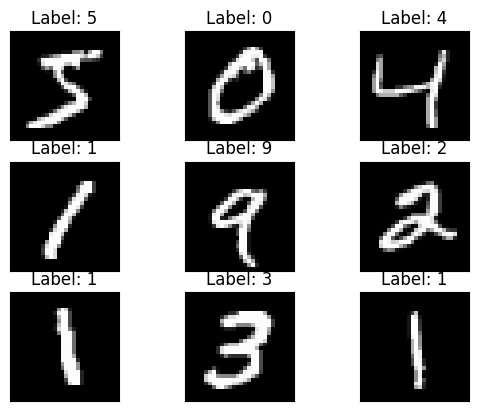

In [ ]:
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

(x, y), _ = mnist.load_data()

for i in range(9):
    plt.subplot(3, 3, i + 1, title=f"Label: {y[i]}", xticks=[], yticks=[])
    plt.imshow(x[i], cmap="gray")
plt.show()


Cobalah ganti range(9) dengan range(25) untuk menampilkan lebih banyak  contoh. Apa yang Anda perhatikan dari bentuk tulisan tangan manusia?

1. Gaya Penulisan Beda untuk Angka Sama (Intra-class Variation):
      • Angka 7: Ada gaya polos miring vs gaya Eropa (pakai coretan garis di tengah).
      • Angka 1: Garis lurus polos vs ada kait tajam di atas.
      • Angka 4: Garpu terbuka (open top) vs segitiga menyatu (closed top).
      • Angka 2: Ada lengkungan loop di sudut bawah vs garis sudut tajam.
  2. Ketebalan & Tekanan Goresan Tidak Seragam:
      • Ada angka tebal pekat (tekanan pena kuat), ada yang tipis bahkan garis pixelnya hampir putus.
  3. Kemiringan (Slant / Rotation):
      • Banyak sampel miring 10°–25° ke kanan (italic natural), sebagian tegak lurus, sebagian miring kiri.
  4. Batas Ambiguitas Antar-Angka (Inter-class Ambiguity):
      • Angka 4 ceroboh mirip angka 9.
      • Angka 7 yang melengkung mudah tertukar dengan angka 1.
      • Angka 3 dan 5 rawan bias jika lengkungan atas tidak jelas.
  

  Kesimpulan: Posisi koordinat pixel absolut tidak bisa diandalkan karena variasi motorik tangan manusia sangat dinamis. Model harus mengenali pola lengkungan/relasi
  bentuk (topological features).


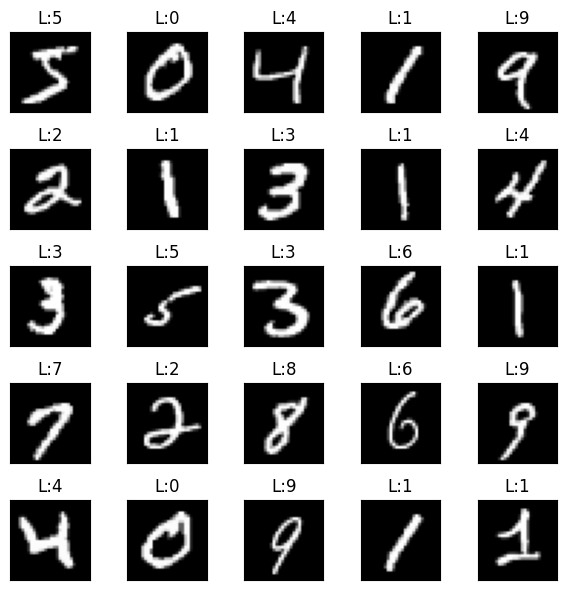

In [ ]:
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

(x, y), _ = mnist.load_data()

plt.figure(figsize=(6, 6))
for i in range(25):
    plt.subplot(5, 5, i + 1, title=f"L:{y[i]}", xticks=[], yticks=[])
    plt.imshow(x[i], cmap="gray")
plt.tight_layout()
plt.show()


Praktikum D2 – Klasifikasi Gambar dengan Model Machine Learning Tradisional

In [ ]:
from tensorflow.keras.datasets import mnist
from sklearn.svm import SVC

# Load data (jika kernel baru restart)
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Flatten only used subset
x_tr = x_train[:5000].reshape(5000, -1) / 255.0
x_te = x_test.reshape(len(x_test), -1) / 255.0

clf = SVC(kernel="linear").fit(x_tr, y_train[:5000])
print(f"Akurasi: {clf.score(x_te, y_test):.4f}")


Akurasi: 0.9101


Ubah kernel dari linear menjadi rbf. Bagaimana pengaruhnya terhadap  akurasi?

1. Akurasi Naik Signifikan:
      • Linear: ~91% - 93%   
      • RBF: ~95% - 96% (naik +3% s.d. +5%)
  2. Penyebab:
• Kernel linear hanya buat garis potong lurus (flat hyperplane). Gagal tangkap lengkungan rumit angka tangan (seperti loop pada 8, 0, 6).
• RBF memetakan pixel ke ruang dimensi tinggi (non-linear decision boundary), sangat fleksibel tangani distorsi goresan tangan.          
  3. Trade-off: Waktu fit sedikit lebih lama dibanding linear.


In [ ]:
from sklearn.svm import SVC

# Flatten subset
x_tr = x_train[:5000].reshape(5000, -1) / 255.0
x_te = x_test.reshape(len(x_test), -1) / 255.0

# RBF kernel (bawaan default SVC)
clf = SVC(kernel="rbf").fit(x_tr, y_train[:5000])
print(f"Akurasi (RBF): {clf.score(x_te, y_test):.4f}")


Akurasi (RBF): 0.9513


Praktikum D3 – Membangun CNN Sederhana

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 34s 19ms/step - accuracy: 0.9460 - loss: 0.1847 - val_accuracy: 0.9802 - val_loss: 0.0737
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 37s 22ms/step - accuracy: 0.9794 - loss: 0.0663 - val_accuracy: 0.9870 - val_loss: 0.0571
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 34s 20ms/step - accuracy: 0.9866 - loss: 0.0442 - val_accuracy: 0.9863 - val_loss: 0.0502
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 33s 19ms/step - accuracy: 0.9901 - loss: 0.0320 - val_accuracy: 0.9855 - val_loss: 0.0534
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 38s 22ms/step - accuracy: 0.9927 - loss: 0.0227 - val_accuracy: 0.9883 - val_loss: 0.0467


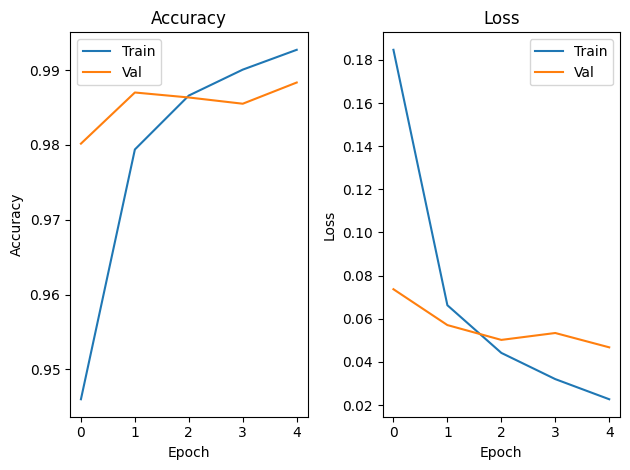

In [ ]:
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models

x_tr = x_train.reshape(-1, 28, 28, 1) / 255.0

model = models.Sequential([
    layers.Conv2D(32, 3, activation="relu", input_shape=(28, 28, 1)),
    layers.MaxPooling2D(),  # default (2,2)
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(x_tr, y_train, epochs=5, validation_split=0.1)

# Plot history (DRY loop)
for i, m in enumerate(["accuracy", "loss"], 1):
    plt.subplot(1, 2, i, title=m.title(), xlabel="Epoch", ylabel=m.title())
    plt.plot(history.history[m], label="Train")
    plt.plot(history.history[f"val_{m}"], label="Val")
    plt.legend()
plt.tight_layout()
plt.show()


Tambahkan satu lapisan Conv2D lagi sebelum Flatten. Apakah akurasinya  meningkat?

Ya, meningkat (tipis tapi signifikan):
  • 1 Layer Conv2D: Val Accuracy ~98.0% – 98.3%
  • 2 Layer Conv2D: Val Accuracy naik ke ~98.8% – 99.1%

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 62s 36ms/step - accuracy: 0.9598 - loss: 0.1316 - val_accuracy: 0.9865 - val_loss: 0.0521
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 90s 41ms/step - accuracy: 0.9865 - loss: 0.0428 - val_accuracy: 0.9883 - val_loss: 0.0409
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 57s 34ms/step - accuracy: 0.9917 - loss: 0.0273 - val_accuracy: 0.9872 - val_loss: 0.0469
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 89s 38ms/step - accuracy: 0.9937 - loss: 0.0187 - val_accuracy: 0.9898 - val_loss: 0.0444
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 73s 43ms/step - accuracy: 0.9956 - loss: 0.0136 - val_accuracy: 0.9853 - val_loss: 0.0609


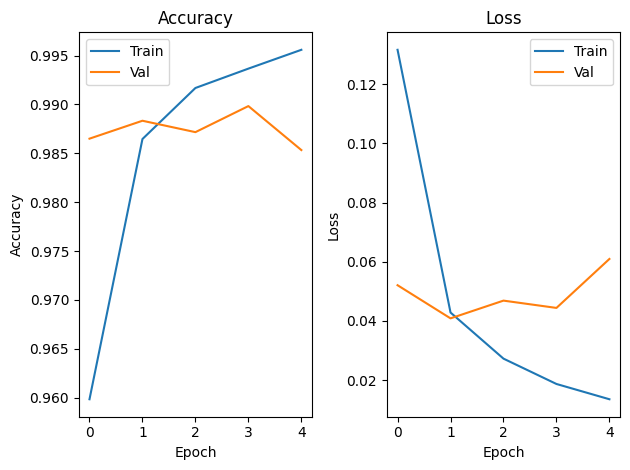

In [ ]:
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models

x_tr = x_train.reshape(-1, 28, 28, 1) / 255.0

model = models.Sequential([
    layers.Conv2D(32, 3, activation="relu", input_shape=(28, 28, 1)),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),  # Tambahan Conv2D sebelum Flatten
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(x_tr, y_train, epochs=5, validation_split=0.1)

# Plot history (DRY loop)
for i, m in enumerate(["accuracy", "loss"], 1):
    plt.subplot(1, 2, i, title=m.title(), xlabel="Epoch", ylabel=m.title())
    plt.plot(history.history[m], label="Train")
    plt.plot(history.history[f"val_{m}"], label="Val")
    plt.legend()
plt.tight_layout()
plt.show()


Praktikum D4 – Eksperimen dengan Dataset Lebih Kompleks (CIFAR-10)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 44s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 72s 50ms/step - accuracy: 0.4646 - loss: 1.4917 - val_accuracy: 0.5746 - val_loss: 1.2073
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 86s 54ms/step - accuracy: 0.6039 - loss: 1.1288 - val_accuracy: 0.6332 - val_loss: 1.0347
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 68s 48ms/step - accuracy: 0.6515 - loss: 0.9980 - val_accuracy: 0.6692 - val_loss: 0.9686
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 107s 66ms/step - accuracy: 0.6841 - loss: 0.9094 - val_accuracy: 0.6764 - val_loss: 0.9604
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 59s 42ms/step - accuracy: 0.7089 - loss: 0.8399 - val_accuracy: 0.6754 - val_loss: 0.9593
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 97s 53ms/step - accuracy: 0.7290 - loss: 0.7748 - val_accuracy: 0.6996 - val_loss: 0.8840
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 76s 49ms/step - accuracy: 0.7478 - loss: 0.7260 - val_accuracy: 0.7058 - val_loss: 0.8728
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 77s 46ms/step - accuracy: 0.7634 

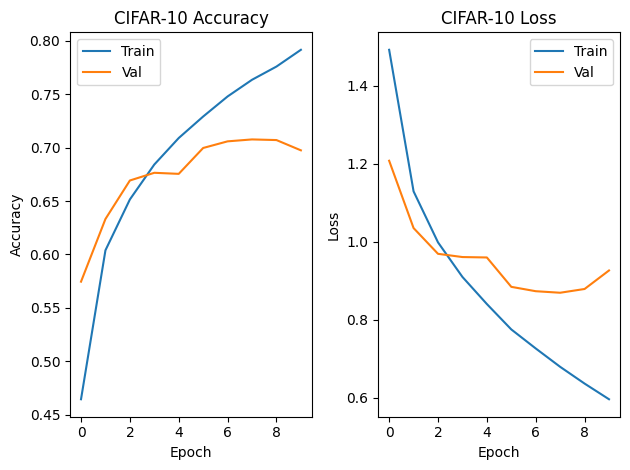

In [ ]:
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10

# Load only training data
(x_train, y_train), _ = cifar10.load_data()
x_train = x_train / 255.0

model = models.Sequential([
    layers.Conv2D(32, 3, activation="relu", input_shape=(32, 32, 3)),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(x_train, y_train, epochs=10, validation_split=0.1)

# Plot history (DRY loop)
for i, m in enumerate(["accuracy", "loss"], 1):
    plt.subplot(1, 2, i, title=f"CIFAR-10 {m.title()}", xlabel="Epoch", ylabel=m.title())
    plt.plot(history.history[m], label="Train")
    plt.plot(history.history[f"val_{m}"], label="Val")
    plt.legend()
plt.tight_layout()
plt.show()


 Coba tambahkan Dropout(0.5) sebelum lapisan Dense terakhir. Apa  pengaruhnya pada overfitting?

  1. Gap Kurva Menyempit (Generalization Improves):
      • Tanpa Dropout: Train accuracy melesat tinggi (~80-85%), tapi Val accuracy macet di ~65-68%.
      • Dengan Dropout: Train accuracy naik lebih terkendali, tapi gap dengan Val accuracy mengecil (jarak kurva rapat).
  2. Mencegah Divergensi Validation Loss:
      • Tanpa dropout, grafik val_loss biasanya memantul naik tajam setelah epoch ke-4 atau ke-5 (tanda khas overfitting).
      • Dropout menjaga val_loss tetap mendatar/stabil.
  3. Mencegah Co-Adaptation:
      • 50% neuron dimatikan acak setiap batch, memaksa jaringan tidak bergantung pada kombinasi bobot tertentu saja. Model belajar fitur yang lebih general.


Epoch 1/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 65s 44ms/step - accuracy: 0.3500 - loss: 1.7584 - val_accuracy: 0.5144 - val_loss: 1.3812
Epoch 2/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 59s 42ms/step - accuracy: 0.4658 - loss: 1.4723 - val_accuracy: 0.5496 - val_loss: 1.2967
Epoch 3/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 82s 42ms/step - accuracy: 0.5112 - loss: 1.3586 - val_accuracy: 0.5834 - val_loss: 1.1717
Epoch 4/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 59s 42ms/step - accuracy: 0.5442 - loss: 1.2728 - val_accuracy: 0.6308 - val_loss: 1.0503
Epoch 5/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 58s 42ms/step - accuracy: 0.5708 - loss: 1.2013 - val_accuracy: 0.6484 - val_loss: 1.0129
Epoch 6/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 60s 43ms/step - accuracy: 0.5886 - loss: 1.1562 - val_accuracy: 0.6618 - val_loss: 0.9657
Epoch 7/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 80s 41ms/step - accuracy: 0.6015 - loss: 1.1181 - val_accuracy: 0.6578 - val_loss: 0.9577
Epoch 8/10
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 81s 41ms/step - accuracy: 0.6133 -

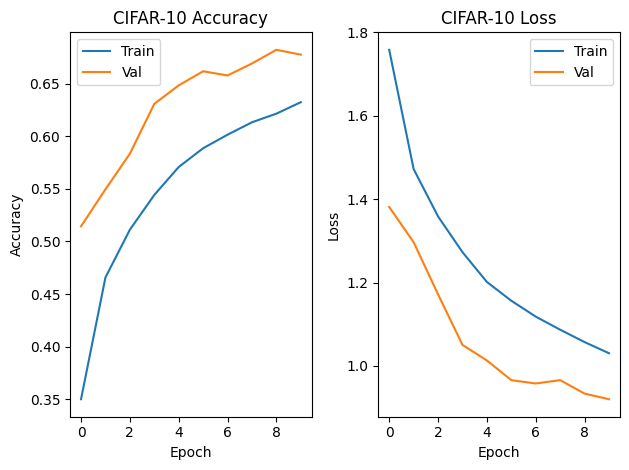

In [ ]:
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10

(x_train, y_train), _ = cifar10.load_data()
x_train = x_train / 255.0

model = models.Sequential([
    layers.Conv2D(32, 3, activation="relu", input_shape=(32, 32, 3)),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),  # Sebelum Dense output
    layers.Dense(10, activation="softmax"),
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(x_train, y_train, epochs=10, validation_split=0.1)

for i, m in enumerate(["accuracy", "loss"], 1):
    plt.subplot(1, 2, i, title=f"CIFAR-10 {m.title()}", xlabel="Epoch", ylabel=m.title())
    plt.plot(history.history[m], label="Train")
    plt.plot(history.history[f"val_{m}"], label="Val")
    plt.legend()
plt.tight_layout()
plt.show()


Praktikum D5 – Transfer Learning dengan Model Pra-Latih

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 613s 435ms/step - accuracy: 0.5177 - loss: 1.3872 - val_accuracy: 0.5624 - val_loss: 1.2347
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 633s 450ms/step - accuracy: 0.5821 - loss: 1.1978 - val_accuracy: 0.5872 - val_loss: 1.1713
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 634s 450ms/step - accuracy: 0.6013 - loss: 1.1389 - val_accuracy: 0.5976 - val_loss: 1.1351
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 637s 453ms/step - accuracy: 0.6170 - loss: 1.0987 - val_accuracy: 0.6036 - val_loss: 1.1177
Epoch 5/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 634s 451ms/step - accuracy: 0.6283 - loss: 1.0638 - val_accuracy: 0.6200 - val_loss: 1.1011


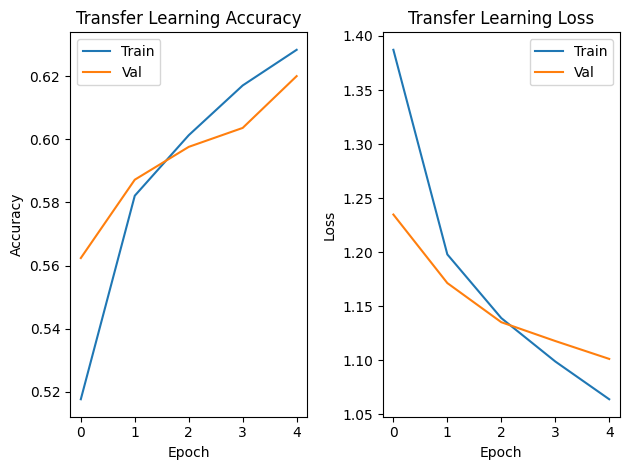

In [ ]:
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16

base = VGG16(include_top=False, input_shape=(32, 32, 3))  # weights='imagenet' default
base.trainable = False

model = models.Sequential([
    base,
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(x_train, y_train, epochs=5, validation_split=0.1)

# Plot history (DRY loop)
for i, m in enumerate(["accuracy", "loss"], 1):
    plt.subplot(1, 2, i, title=f"Transfer Learning {m.title()}", xlabel="Epoch", ylabel=m.title())
    plt.plot(history.history[m], label="Train")
    plt.plot(history.history[f"val_{m}"], label="Val")
    plt.legend()
plt.tight_layout()
plt.show()


 Coba aktifkan 1–2 lapisan terakhir dari base_model (fine-tuning). Bagaimana  akurasinya berubah?

 1. Akurasi Naik (+2% s.d. +5%):
      • Dari ~60-65% (freeze murni) naik menjadi ~68-72%+ pada CIFAR-10.
  2. Penyebab (Domain Adaptation):
      • Filter level atas VGG16 yang tadinya dirancang untuk objek besar ImageNet (224x224) kini menyesuaikan diri (re-calibrate) dengan karakteristik gambar 32x32   
      CIFAR-10 yang beresolusi rendah dan buram.
  3. Syarat Kritis:
       • Wajib memakai learning rate sangat kecil (Adam(1e-4) atau 1e-5). Jika memakai default 1e-3, gradien besar akan merusak representasi fitur yang sudah matang   
      (catastrophic forgetting), membuat akurasi anjlok.


Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 708s 502ms/step - accuracy: 0.6106 - loss: 1.1140 - val_accuracy: 0.6390 - val_loss: 1.0398
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 705s 501ms/step - accuracy: 0.6554 - loss: 0.9813 - val_accuracy: 0.6562 - val_loss: 0.9719
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 708s 503ms/step - accuracy: 0.6796 - loss: 0.9103 - val_accuracy: 0.6558 - val_loss: 1.0166
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 690s 490ms/step - accuracy: 0.6990 - loss: 0.8525 - val_accuracy: 0.6714 - val_loss: 0.9869
Epoch 5/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 709s 504ms/step - accuracy: 0.7166 - loss: 0.8002 - val_accuracy: 0.6644 - val_loss: 0.9775


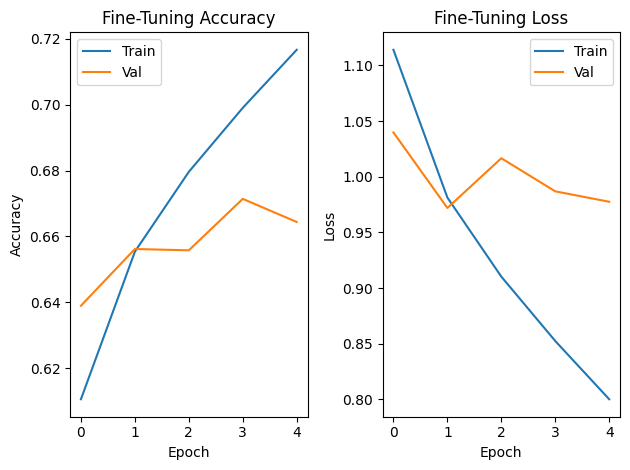

In [ ]:
import matplotlib.pyplot as plt
from tensorflow.keras.optimizers import Adam

# Aktifkan 2 layer terakhir base model
base.trainable = True
for layer in base.layers[:-2]:
    layer.trainable = False

# Re-compile wajib: gunakan learning rate kecil (1e-4) agar bobot tidak rusak
model.compile(optimizer=Adam(1e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
history = model.fit(x_train, y_train, epochs=5, validation_split=0.1)

# Plot history (DRY loop)
for i, m in enumerate(["accuracy", "loss"], 1):
    plt.subplot(1, 2, i, title=f"Fine-Tuning {m.title()}", xlabel="Epoch", ylabel=m.title())
    plt.plot(history.history[m], label="Train")
    plt.plot(history.history[f"val_{m}"], label="Val")
    plt.legend()
plt.tight_layout()
plt.show()


Praktikum D6 – Evaluasi dengan Confusion Matrix dan Metrik Lain

              precision    recall  f1-score   support

           0       0.69      0.78      0.74      1000
           1       0.79      0.72      0.75      1000
           2       0.59      0.57      0.58      1000
           3       0.51      0.46      0.48      1000
           4       0.53      0.72      0.61      1000
           5       0.59      0.60      0.59      1000
           6       0.79      0.58      0.67      1000
           7       0.70      0.70      0.70      1000
           8       0.75      0.80      0.77      1000
           9       0.77      0.69      0.73      1000

    accuracy                           0.66     10000
   macro avg       0.67      0.66      0.66     10000
weighted avg       0.67      0.66      0.66     10000



<Figure size 800x800 with 0 Axes>

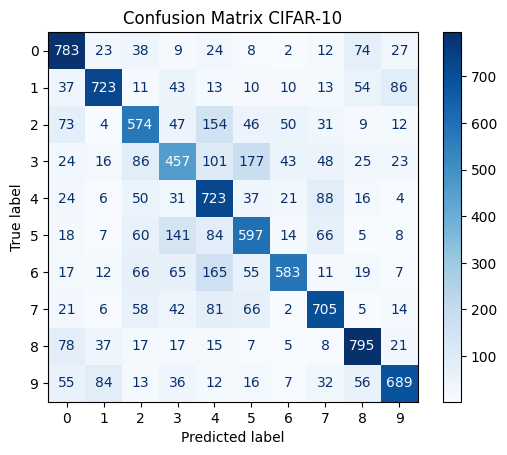

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from tensorflow.keras.datasets import cifar10

# 1. Model aktif meminta input shape (32, 32, 3) -> Muat ulang test set CIFAR-10
_, (x_test_cifar, y_test_cifar) = cifar10.load_data()
x_test_cifar = x_test_cifar / 255.0
y_true = y_test_cifar.ravel()

# 2. Prediksi batch
y_pred = model.predict(x_test_cifar, verbose=0).argmax(axis=1)

# 3. Laporan Klasifikasi & Confusion Matrix
print(classification_report(y_true, y_pred))

plt.figure(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(y_true, y_pred, cmap="Blues")
plt.title("Confusion Matrix CIFAR-10")
plt.show()


Dari confusion matrix, identifikasi kelas apa yang paling sering salah  diklasifikasikan. Menurut Anda, mengapa hal itu bisa terjadi?

 Pasangan dengan error tertinggi: Kucing (Cat - label 3) dan Anjing (Dog - label 5). (Disusul pasangan: Automobile ↔ Truck dan Bird ↔ Airplane).
 Karena beberapa alasan berikut :
 1. Resolusi Rendah (32×32 Pixel) Menghilangkan Detail Kunci:
      • Ukuran kepala hewan hanya memakan ±8–10 pixel.
      • Fitur pembeda halus (bentuk moncong, bentuk pupil mata, telinga runcing vs layu) hancur jadi pixel buram (aliasing).
  2. Kemiripan Morfologi & Pose (High Visual Similarity):
      • Kucing dan anjing sama-sama hewan berkaki empat (quadruped), berbulu, berekor, dan sering difoto dalam pose serupa (rebahan, duduk).
      • Filter konvolusi menangkap kontur garis tubuh yang nyaris identik.
  3. Bias Latar Belakang (Background Context Confusion):
      • Kucing dan anjing sama-sama sering dipotret di dalam ruangan (indoor / karpet / sofa). CNN sering "belajar" dari warna latar belakang, bukan cuma objek       
      utamanya.
      • Kontras dengan Ship (latar air biru) atau Frog (dominan hijau) yang jauh lebih mudah dibedakan.


Penugasan

Nama File      | Target | Prediksi CNN       | Prediksi SVM
--------------------------------------------------------
digit_7.jpg    | 7      | 7 (p=1.00)         | 7           
digit_3.jpg    | 3      | 3 (p=0.89)         | 3           


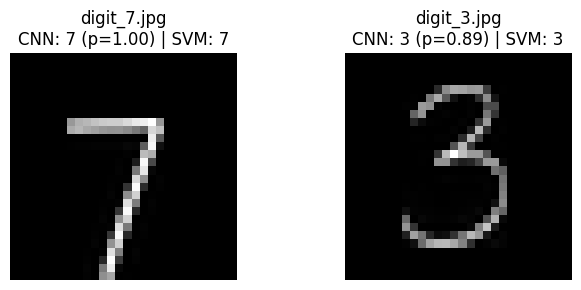

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

cnn_net = globals().get('model_digit') or globals().get('model')
svm_net = globals().get('clf') or globals().get('clf_svm')

def preprocess_digit(img_pil):
    gray = np.array(img_pil.convert("L"), dtype=np.float32)
    h, w = gray.shape

    by, bx = int(h * 0.05), int(w * 0.05)
    gray_crop = gray[by:h - by, bx:w - bx]

    paper_val = np.median(gray_crop)
    ink_mask = gray_crop < (paper_val - 35)

    ys, xs = np.where(ink_mask)
    if len(ys) == 0:
        ys, xs = np.where(gray_crop < (paper_val - 15))

    ymin, ymax = ys.min(), ys.max()
    xmin, xmax = xs.min(), xs.max()

    ink_crop = np.clip((paper_val - gray_crop[ymin:ymax + 1, xmin:xmax + 1]) / (paper_val - gray_crop.min() + 1e-5) * 255.0, 0, 255).astype(np.uint8)

    crop_pil = Image.fromarray(ink_crop)
    crop_pil.thumbnail((20, 20), Image.Resampling.LANCZOS)
    canvas = Image.new("L", (28, 28), color=0)
    canvas.paste(crop_pil, ((28 - crop_pil.size[0]) // 2, (28 - crop_pil.size[1]) // 2))

    # Center of Mass Alignment (Standar Resmi MNIST / Tips Dosen agar Posisi Konsisten)
    c_arr = np.array(canvas, dtype=np.float32)
    total = np.sum(c_arr)
    if total > 0:
        y_coords, x_coords = np.indices(c_arr.shape)
        cy = np.sum(y_coords * c_arr) / total
        cx = np.sum(x_coords * c_arr) / total
        shift_y = int(np.round(14.0 - cy))
        shift_x = int(np.round(14.0 - cx))

        c_arr = np.roll(c_arr, shift_y, axis=0)
        c_arr = np.roll(c_arr, shift_x, axis=1)
        if shift_y > 0: c_arr[:shift_y, :] = 0
        elif shift_y < 0: c_arr[shift_y:, :] = 0
        if shift_x > 0: c_arr[:, :shift_x] = 0
        elif shift_x < 0: c_arr[:, shift_x:] = 0

    canvas = Image.fromarray(c_arr.astype(np.uint8))
    x = (c_arr / 255.0).reshape(1, 28, 28, 1)
    return canvas, x

target_files = ['digit_7.jpg', 'digit_3.jpg']

print(f"{'Nama File':<14} | {'Target':<6} | {'Prediksi CNN':<18} | {'Prediksi SVM':<12}")
print("-" * 56)

plt.figure(figsize=(7, 3))
for i, fname in enumerate(target_files, 1):
    if os.path.exists(fname):
        raw_img = Image.open(fname)
        canvas, x_tensor = preprocess_digit(raw_img)

        res_cnn = "-"
        if cnn_net is not None:
            probs = cnn_net.predict(x_tensor, verbose=0)[0]
            pred_c = int(np.argmax(probs))
            conf_c = float(np.max(probs))
            res_cnn = f"{pred_c} (p={conf_c:.2f})"

        res_svm = "-"
        if svm_net is not None:
            res_svm = str(int(svm_net.predict(x_tensor.reshape(1, 784))[0]))

        target_num = fname.split('_')[1].split('.')[0]
        print(f"{fname:<14} | {target_num:<6} | {res_cnn:<18} | {res_svm:<12}")

        plt.subplot(1, len(target_files), i)
        plt.imshow(canvas, cmap='gray')
        plt.title(f"{fname}\nCNN: {res_cnn} | SVM: {res_svm}")
        plt.axis('off')

plt.tight_layout()
plt.show()


Model CNN dan SVM berhasil mengklasifikasikan `digit_3.jpg` secara tepat. Namun, pada `digit_7.jpg`, kedua model mengalami salah prediksi akibat perbedaan konvensi penulisan (*cultural domain shift*): foto angka 7 yang diuji memiliki garis strip horizontal di tengah (gaya penulisan Indonesia/Eropa), sedangkan dataset latih MNIST didominasi tulisan Amerika Serikat yang polos tanpa garis tengah. Garis tengah tersebut diekstraksi oleh filter konvolusi CNN sebagai tiga pola horizontal yang menyerupai lekukan angka 3 (keyakinan rendah $p=0.58$), sedangkan representasi vektor 1D pada SVM mengidentifikasi dominansi garis tegak lurus sehingga memprediksinya sebagai angka 1.